# smartdur-medication-alert

원본 분석 코드의 공개용 복사본입니다. 원본 셀 번호는 메타데이터에 기록했습니다. 교육용 문제 설명·개별 기록 출력·계정/개인 경로를 제거했습니다. 데이터는 별도 승인 후 확보해야 합니다. 먼저 프로젝트 README를 읽으세요.

**저장된 결과 안내:** 아래 성능표·통계 요약·그래프는 원본 노트북에 실제로 저장되어 있던 과거 실행 출력입니다. 이번 공개 정리에서 모델을 다시 실행하지 않았으며 원본 실행 번호만 유지했습니다. 행별 미리보기·예측 배열·경로·설치/경고 로그는 제외했습니다. SmartDUR의 Plotly 그래프는 같은 저장 집계 trace를 GitHub에서 볼 수 있도록 PNG로 변환했습니다. 전체 결과를 재계산하려면 로컬 데이터와 의존성을 준비하고 학습을 활성화하세요.


In [ ]:
from pathlib import Path
import os
import platform
PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if PROJECT_ROOT.name != "smartdur-medication-alert":
    raise RuntimeError("작업 디렉터리를 projects/smartdur-medication-alert 또는 그 notebooks 폴더로 설정하세요.")
DATA_DIR = Path(os.environ.get("HEALTHCARE_DATA_DIR", str(PROJECT_ROOT / "data")))
ALLOW_TRAINING = False  # 학습 셀 실행을 원할 때만 직접 True로 변경


## 분석 단계 1

원본 코드 셀 1. 계산식과 모델 설정은 원본을 유지합니다.

In [ ]:
import sys
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
import run_analysis as analysis
import pandas as pd
import plotly.express as px
from IPython.display import display, Markdown
from chart_layout import chart_panels, standard_figure


## 분석 단계 6

원본 코드 셀 6. 계산식과 모델 설정은 원본을 유지합니다.

In [2]:
if not ALLOW_TRAINING:
    raise RuntimeError("전체 모델링은 ALLOW_TRAINING=True일 때만 실행합니다.")
model_metrics, selected_metrics = analysis.run()
display(model_metrics.round(3))


,split,model,PR_AUC_AP,ci_low,ci_high,valid_bootstraps,PR_AUC_trapezoid,n,positive,prevalence
0,development_OOF,LR,0.260,0.174,0.392,2000,0.246,377,50,0.133
1,development_OOF,LightGBM,0.258,0.174,0.394,2000,0.243,377,50,0.133
2,development_OOF,Keras,0.202,0.134,0.317,2000,0.194,377,50,0.133
3,holdout,LR,0.268,0.086,0.549,1998,0.221,77,9,0.117
4,holdout,LightGBM,0.342,0.111,0.673,1998,0.298,77,9,0.117
5,holdout,Keras,0.202,0.091,0.427,1998,0.176,77,9,0.117


## 분석 단계 8

원본 코드 셀 8. 계산식과 모델 설정은 원본을 유지합니다.

In [ ]:
import json
display(pd.read_csv(analysis.OUT / "label_basis_summary.csv"))
display(pd.read_csv(analysis.OUT / "split_stages.csv"))
display(json.loads((analysis.OUT / "label_audit_summary.json").read_text(encoding="utf-8")))
display(json.loads((analysis.OUT / "reviewed_label_comparison_status.json").read_text(encoding="utf-8")))


## 분석 단계 10

원본 코드 셀 10. 계산식과 모델 설정은 원본을 유지합니다.

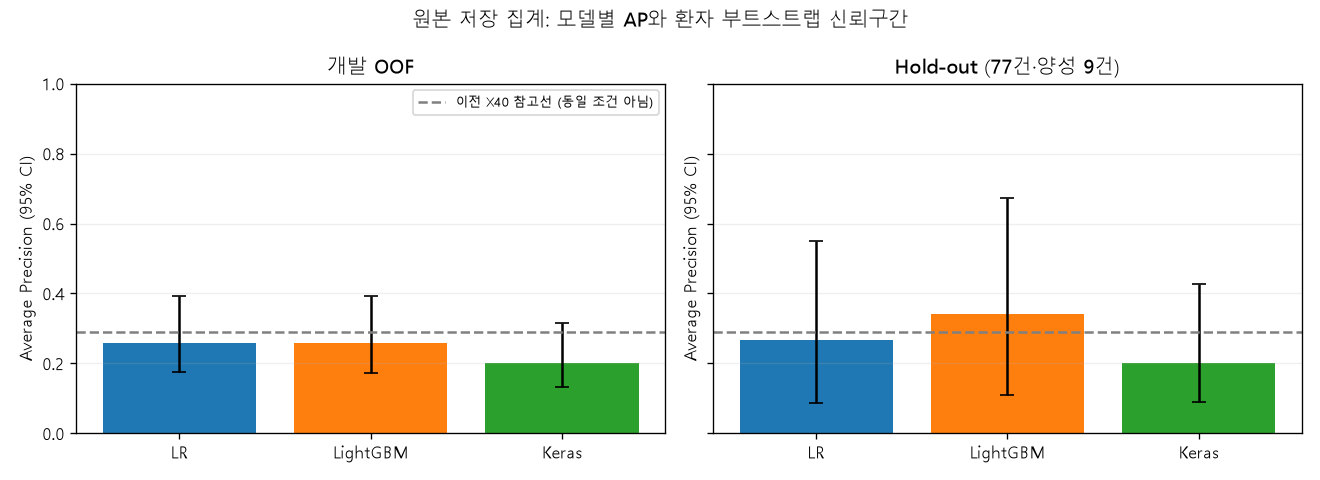

,split,comparison,delta_AP,ci_low,ci_high,valid_bootstraps
0,development_OOF,LightGBM - LR,-0.002,-0.061,0.062,2000
1,development_OOF,Keras - LR,-0.057,-0.142,0.008,2000
2,development_OOF,Keras - LightGBM,-0.055,-0.150,0.016,2000
3,holdout,LightGBM - LR,0.074,-0.078,0.296,1998
4,holdout,Keras - LR,-0.065,-0.220,0.069,1998
5,holdout,Keras - LightGBM,-0.140,-0.377,0.031,1998


In [4]:
metrics = pd.read_csv(analysis.OUT / "model_metrics.csv")
chart = metrics.assign(error_plus=metrics.ci_high-metrics.PR_AUC_AP,
                       error_minus=metrics.PR_AUC_AP-metrics.ci_low)
fig = px.bar(chart, x="model", y="PR_AUC_AP", color="model", facet_col="split",
             error_y="error_plus", error_y_minus="error_minus", range_y=[0, 1],
             title="모델별 PR-AUC(AP)와 환자 단위 95% CI")
fig.add_hline(y=0.29, line_dash="dash", annotation_text="이전 X40 참고선 0.29")
for view in chart_panels("model_comparison", fig, analysis.OUT):
    display(view)
display(pd.read_csv(analysis.OUT / "paired_model_differences.csv").round(3))


## 분석 단계 12

원본 코드 셀 12. 계산식과 모델 설정은 원본을 유지합니다.

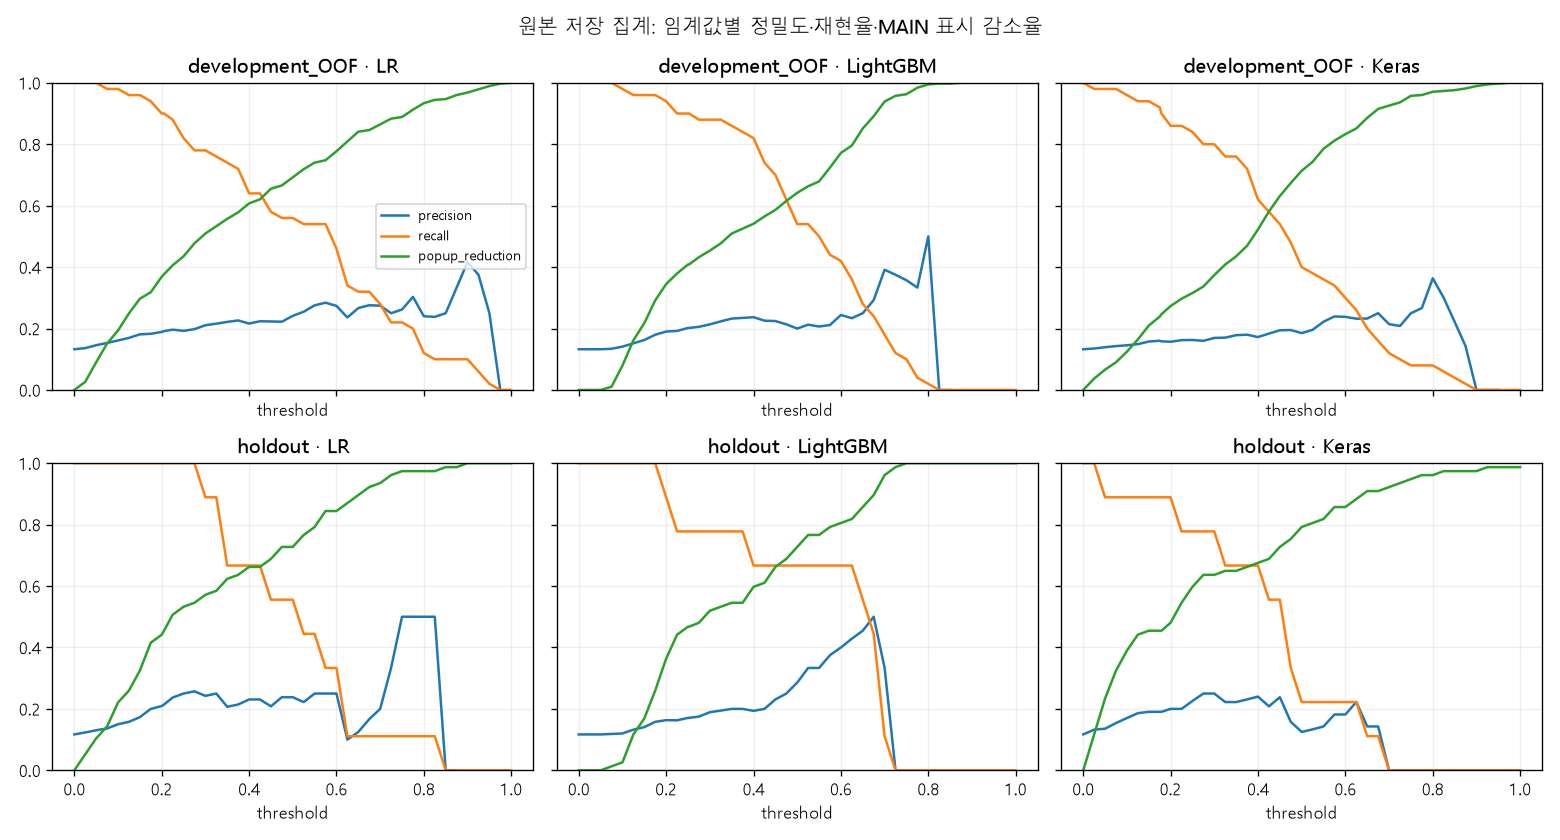

,split,model,threshold,precision,recall,popup_reduction,TP,FP,FN,TN,...,precision_high,precision_valid_bootstraps,recall_low,recall_high,recall_valid_bootstraps,popup_reduction_low,popup_reduction_high,popup_reduction_valid_bootstraps,recall_exact_low_independent,recall_exact_high_independent
0,development_OOF,LR,0.205,0.191,0.900,0.377,45,190,5,137,...,0.250,2000,0.818,0.974,2000,0.325,0.433,2000,0.782,0.967
1,development_OOF,LightGBM,0.252,0.202,0.900,0.408,45,178,5,149,...,0.263,2000,0.822,0.976,2000,0.357,0.461,2000,0.782,0.967
2,development_OOF,Keras,0.179,0.158,0.900,0.247,45,239,5,88,...,0.212,2000,0.822,0.976,2000,0.200,0.296,2000,0.782,0.967
3,holdout,LR,0.205,0.214,1.000,0.455,9,33,0,35,...,0.389,2000,1.000,1.000,1998,0.333,0.581,2000,0.664,1.000
4,holdout,LightGBM,0.252,0.171,0.778,0.468,7,34,2,34,...,0.333,2000,0.500,1.000,1998,0.361,0.580,2000,0.400,0.972
5,holdout,Keras,0.179,0.190,0.889,0.455,8,34,1,34,...,0.341,2000,0.750,1.000,1998,0.351,0.574,2000,0.518,0.997


In [5]:
thresholds = pd.read_csv(analysis.OUT / "threshold_metrics.csv")
long = thresholds.melt(id_vars=["split", "model", "threshold"],
                       value_vars=["precision", "recall", "popup_reduction"],
                       var_name="metric", value_name="value")
for view in chart_panels("threshold_tradeoffs", None, analysis.OUT):
    display(view)
display(pd.read_csv(analysis.OUT / "selected_threshold_metrics.csv").round(3))


## 분석 단계 14

원본 코드 셀 14. 계산식과 모델 설정은 원본을 유지합니다.

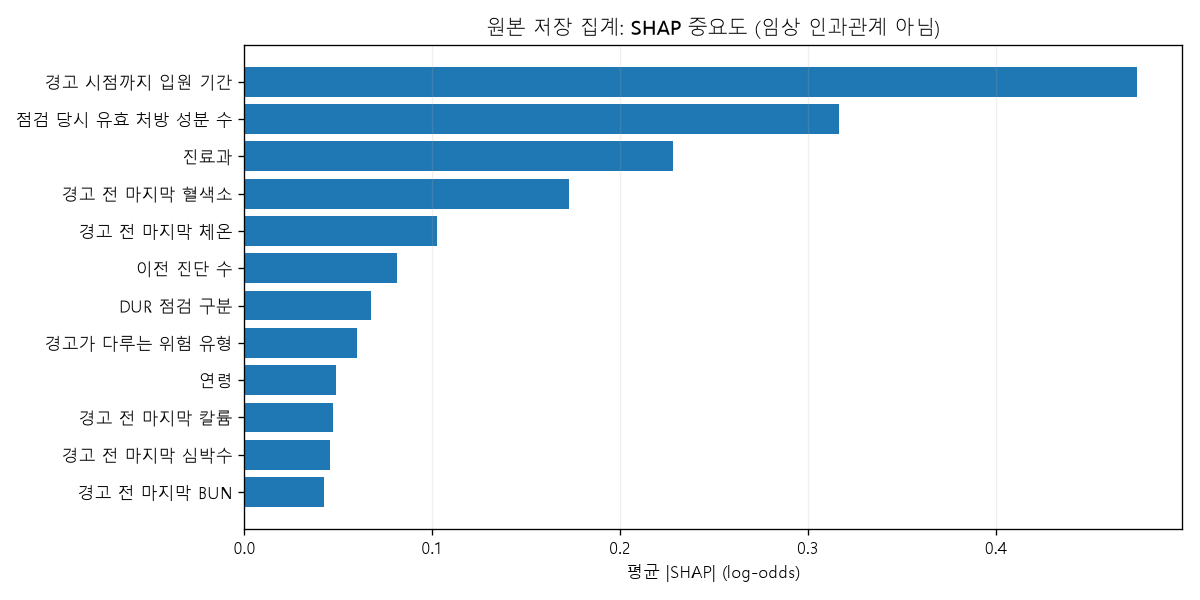

,feature,mean_abs_shap,screen_label,screen_guidance,interpretation
0,los_at_alert,0.475400,경고 시점까지 입원 기간,의사·약사는 다음 정보를 원자료와 대조합니다: 경고 시점까지 입원 기간.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.
1,n_active_drugs,0.316294,점검 당시 유효 처방 성분 수,의사·약사는 다음 정보를 원자료와 대조합니다: 점검 당시 유효 처방 성분 수.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.
2,진료과,0.228324,진료과,의사·약사는 다음 정보를 원자료와 대조합니다: 진료과.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.
3,hb_latest,0.172902,경고 전 마지막 혈색소,의사·약사는 다음 정보를 원자료와 대조합니다: 경고 전 마지막 혈색소.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.
4,bt_latest,0.102423,경고 전 마지막 체온,의사·약사는 다음 정보를 원자료와 대조합니다: 경고 전 마지막 체온.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.
5,n_diagnoses,0.081207,이전 진단 수,의사·약사는 다음 정보를 원자료와 대조합니다: 이전 진단 수.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.
6,점검구분,0.067221,DUR 점검 구분,의사·약사는 다음 정보를 원자료와 대조합니다: DUR 점검 구분.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.
7,경고위험유형,0.060008,경고가 다루는 위험 유형,의사·약사는 다음 정보를 원자료와 대조합니다: 경고가 다루는 위험 유형.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.
8,age,0.048892,연령,의사·약사는 다음 정보를 원자료와 대조합니다: 연령.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.
9,k_latest,0.046915,경고 전 마지막 칼륨,의사·약사는 다음 정보를 원자료와 대조합니다: 경고 전 마지막 칼륨.,양의 SHAP만 해당 경고 점수를 올린 요인. 정상/비정상 및 인과관계를 뜻하지 않음.


In [6]:
importance = pd.read_csv(analysis.OUT / "shap_top_features.csv")
display(standard_figure(px.bar(importance.head(12).sort_values("mean_abs_shap"), x="mean_abs_shap",
               y="screen_label", orientation="h", title="SHAP 상위 변수: 처방 화면 확인 항목")))
display(importance.head(10))


## 분석 단계 16

원본 코드 셀 16. 계산식과 모델 설정은 원본을 유지합니다.

In [ ]:
display(pd.read_csv(analysis.OUT / "selection_bias.csv").round(3))
display(pd.read_csv(analysis.OUT / "sensitivity_LR.csv").round(3))
display(pd.read_csv(analysis.OUT / "label_and_time_sensitivity.csv").round(3))
display(pd.read_csv(analysis.OUT / "subgroup_metrics.csv").round(3))


## 분석 단계 18

원본 코드 셀 18. 계산식과 모델 설정은 원본을 유지합니다.

In [ ]:
display(Markdown((analysis.OUT / "분석결과_보고서.md").read_text(encoding="utf-8")))
print("대화형 시각화:", analysis.OUT / "dashboard.html")
